In [1]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ARCHIVE = Path('OC-20250526T142605Z-1-001.zip')
if not ARCHIVE.exists():
    ARCHIVE = Path('/mnt/data/OC-20250526T142605Z-1-001.zip')
assert ARCHIVE.exists(), 'Placez le ZIP OpenClassrooms à côté du notebook.'

def read_nested_csv(archive_path, internal_zip, csv_file):
    with zipfile.ZipFile(archive_path) as parent:
        nested_bytes = parent.read(internal_zip)
    with zipfile.ZipFile(io.BytesIO(nested_bytes)) as inner:
        return pd.read_csv(inner.open(csv_file))

df = read_nested_csv(ARCHIVE, 'OC/Agriculture Crop Yield.zip', 'crop_yield.csv')
print('Dimensions :', df.shape)
display(df.head())

Dimensions : (1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
print('Types :')
display(df.dtypes.to_frame('type'))
print('Valeurs manquantes :')
display(df.isna().sum().to_frame('manquants'))
print('Doublons exacts :', df.duplicated().sum())
print('Rendements négatifs :', (df['Yield_tons_per_hectare'] < 0).sum())
display(df.describe(include='all').T)

df_clean = df.loc[df['Yield_tons_per_hectare'] >= 0].copy()
print('Lignes conservées pour la régression :', len(df_clean))

Types :


,type
Region,str
Soil_Type,str
Crop,str
Rainfall_mm,float64
Temperature_Celsius,float64
Fertilizer_Used,bool
Irrigation_Used,bool
Weather_Condition,str
Days_to_Harvest,int64
Yield_tons_per_hectare,float64


Valeurs manquantes :


,manquants
Region,0
Soil_Type,0
Crop,0
Rainfall_mm,0
Temperature_Celsius,0
Fertilizer_Used,0
Irrigation_Used,0
Weather_Condition,0
Days_to_Harvest,0
Yield_tons_per_hectare,0


Doublons exacts : 0
Rendements négatifs : 231


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,1000000,4,North,250173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Type,1000000,6,Sandy,167119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,1000000,6,Maize,166824,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rainfall_mm,1000000.0,NaN,NaN,NaN,549.981901,259.85132,100.000896,324.89109,550.124061,774.73852,999.998098
Temperature_Celsius,1000000.0,NaN,NaN,NaN,27.504965,7.220608,15.000034,21.254502,27.507365,33.753267,39.999997
Fertilizer_Used,1000000,2,False,500060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Irrigation_Used,1000000,2,False,500509,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather_Condition,1000000,3,Sunny,333790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days_to_Harvest,1000000.0,NaN,NaN,NaN,104.495025,25.953412,60.0,82.0,104.0,127.0,149.0
Yield_tons_per_hectare,1000000.0,NaN,NaN,NaN,4.649472,1.696572,-1.147613,3.417637,4.651808,5.8792,9.963372


Lignes conservées pour la régression : 999769


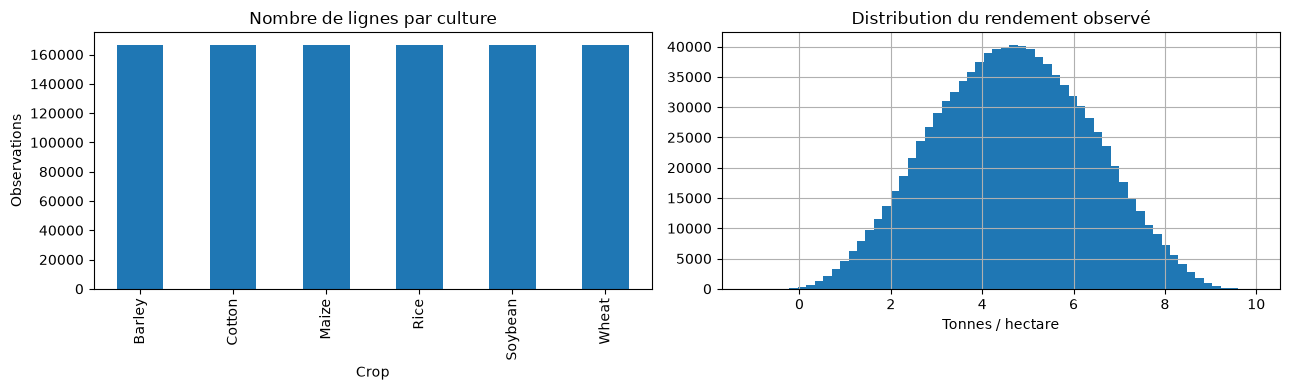

,size,mean,std,min,max
Crop,,,,,
Barley,166777,4.647,1.698,-0.819,9.949
Cotton,166585,4.651,1.695,-0.590,9.786
Maize,166824,4.641,1.696,-0.875,9.953
Rice,166792,4.651,1.698,-0.468,9.963
Soybean,166349,4.654,1.697,-0.596,9.678
Wheat,166673,4.653,1.695,-1.148,9.803


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df['Crop'].value_counts().sort_index().plot.bar(ax=axes[0], title='Nombre de lignes par culture')
axes[0].set_ylabel('Observations')
df['Yield_tons_per_hectare'].hist(ax=axes[1], bins=60)
axes[1].set_title('Distribution du rendement observé')
axes[1].set_xlabel('Tonnes / hectare')
plt.tight_layout()
plt.show()

display(df.groupby('Crop')['Yield_tons_per_hectare'].agg(['size', 'mean', 'std', 'min', 'max']).round(3))

In [4]:
for column in ['Region', 'Soil_Type', 'Weather_Condition', 'Irrigation_Used', 'Fertilizer_Used']:
    tab = pd.crosstab(df[column], df['Crop'], normalize='index')
    print(f'\n{column} — proportion des cultures par modalité (%)')
    display((tab * 100).round(2))

print('Moyenne et écart-type des précipitations par culture :')
display(df.groupby('Crop')[['Rainfall_mm', 'Temperature_Celsius']].agg(['mean', 'std']).round(2))


Region — proportion des cultures par modalité (%)


Crop,Barley,Cotton,Maize,Rice,Soybean,Wheat
Region,,,,,,
East,16.66,16.76,16.63,16.63,16.81,16.51
North,16.70,16.61,16.72,16.76,16.44,16.78
South,16.68,16.60,16.69,16.68,16.65,16.71
West,16.68,16.67,16.69,16.65,16.64,16.67



Soil_Type — proportion des cultures par modalité (%)


Crop,Barley,Cotton,Maize,Rice,Soybean,Wheat
Soil_Type,,,,,,
Chalky,16.63,16.68,16.72,16.64,16.81,16.52
Clay,16.67,16.67,16.61,16.81,16.64,16.61
Loam,16.72,16.67,16.73,16.63,16.65,16.60
Peaty,16.75,16.65,16.73,16.59,16.49,16.78
Sandy,16.61,16.73,16.63,16.64,16.61,16.80
Silt,16.68,16.55,16.68,16.77,16.62,16.70



Weather_Condition — proportion des cultures par modalité (%)


Crop,Barley,Cotton,Maize,Rice,Soybean,Wheat
Weather_Condition,,,,,,
Cloudy,16.65,16.58,16.63,16.63,16.73,16.77
Rainy,16.74,16.67,16.69,16.69,16.65,16.56
Sunny,16.64,16.72,16.73,16.72,16.53,16.67


... (2 outputs left out)


Fertilizer_Used — proportion des cultures par modalité (%)


Crop,Barley,Cotton,Maize,Rice,Soybean,Wheat
Fertilizer_Used,,,,,,
False,16.70,16.64,16.73,16.66,16.64,16.63
True,16.65,16.68,16.63,16.69,16.63,16.71


Moyenne et écart-type des précipitations par culture :


Rainfall_mm         Temperature_Celsius      
               mean     std                mean   std
Crop                                                 
Barley       549.56  259.77               27.50  7.22
Cotton       549.90  260.23               27.53  7.23
Maize        549.20  259.90               27.48  7.22
Rice         550.51  259.84               27.50  7.20
Soybean      550.47  259.60               27.51  7.23
Wheat        550.25  259.77               27.52  7.22

In [5]:
context_features = ['Region', 'Soil_Type', 'Rainfall_mm', 'Temperature_Celsius', 'Weather_Condition']
planned_features = ['Fertilizer_Used', 'Irrigation_Used']
features_clf = context_features + planned_features
features_reg = context_features + planned_features + ['Crop']

def pipeline_for_features(X, estimator, scale_numeric=False):
    cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
    num_cols = [c for c in X.columns if c not in cat_cols]
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        num_steps.append(('scaler', StandardScaler()))
    preprocessing = ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ])
    return Pipeline([('preprocess', preprocessing), ('model', estimator)])

print('Features classification :', features_clf)
print('Features régression :', features_reg)

Features classification : ['Region', 'Soil_Type', 'Rainfall_mm', 'Temperature_Celsius', 'Weather_Condition', 'Fertilizer_Used', 'Irrigation_Used']
Features régression : ['Region', 'Soil_Type', 'Rainfall_mm', 'Temperature_Celsius', 'Weather_Condition', 'Fertilizer_Used', 'Irrigation_Used', 'Crop']


C:\Users\mouto\AppData\Local\Temp\ipykernel_12520\2846068558.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
C:\Users\mouto\AppData\Local\Temp\ipykernel_12520\2846068558.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://panda

,model,accuracy,f1_macro
0,Dummy (most_frequent),0.167700,0.047872
1,Logistic Regression,0.167633,0.158607


              precision    recall  f1-score   support

      Barley       0.16      0.16      0.16      5004
      Cotton       0.17      0.17      0.17      5023
       Maize       0.18      0.13      0.15      4991
        Rice       0.17      0.20      0.19      5000
     Soybean       0.16      0.29      0.21      5031
       Wheat       0.15      0.05      0.07      4951

    accuracy                           0.17     30000
   macro avg       0.17      0.17      0.16     30000
weighted avg       0.17      0.17      0.16     30000



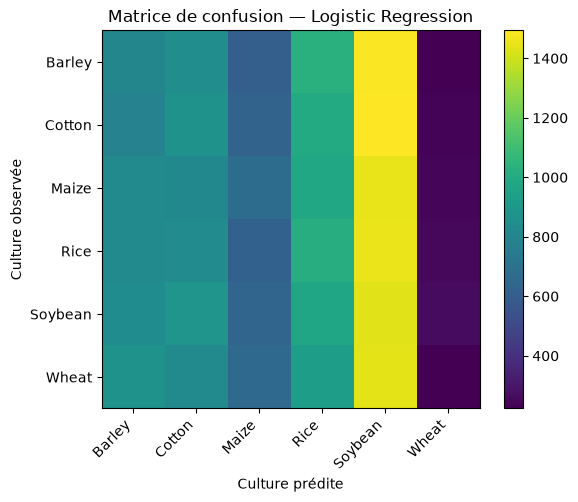

In [6]:
clf_sample = df.sample(n=min(120_000, len(df)), random_state=SEED)
X = clf_sample[features_clf]
y = clf_sample['Crop']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

classifiers = {
    'Dummy (most_frequent)': pipeline_for_features(X_train, DummyClassifier(strategy='most_frequent')),
    'Logistic Regression': pipeline_for_features(X_train, LogisticRegression(max_iter=400), scale_numeric=True),
}
clf_results = []
for name, model in classifiers.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    clf_results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'f1_macro': f1_score(y_test, pred, average='macro', zero_division=0),
    })
display(pd.DataFrame(clf_results).sort_values('accuracy', ascending=False))

best_clf = classifiers['Logistic Regression']
pred = best_clf.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
classes = sorted(y_test.unique())
cm = confusion_matrix(y_test, pred, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set_xticks(range(len(classes)), classes, rotation=45, ha='right')
ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel('Culture prédite')
ax.set_ylabel('Culture observée')
ax.set_title('Matrice de confusion — Logistic Regression')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

C:\Users\mouto\AppData\Local\Temp\ipykernel_12520\2846068558.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
C:\Users\mouto\AppData\Local\Temp\ipykernel_12520\2846068558.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://panda

,model,MAE (t/ha),RMSE (t/ha),R2
1,Linear Regression,0.397813,0.499095,0.912937
0,Dummy (mean),1.385643,1.691486,-0.000005


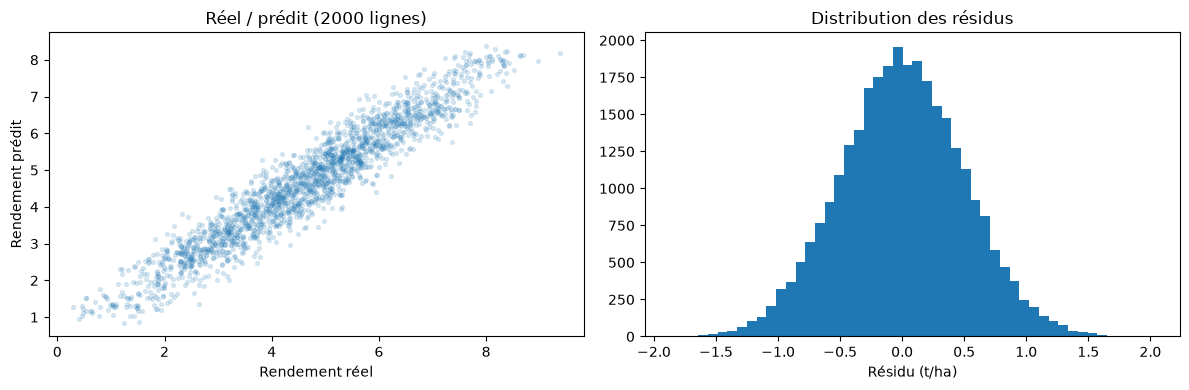

In [7]:
reg_sample = df_clean.sample(n=min(120_000, len(df_clean)), random_state=SEED)
Xr = reg_sample[features_reg]
yr = reg_sample['Yield_tons_per_hectare']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.25, random_state=SEED
)
regressors = {
    'Dummy (mean)': pipeline_for_features(Xr_train, DummyRegressor(strategy='mean')),
    'Linear Regression': pipeline_for_features(Xr_train, LinearRegression()),
}
reg_results = []
for name, model in regressors.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_results.append({
        'model': name,
        'MAE (t/ha)': mean_absolute_error(yr_test, pred),
        'RMSE (t/ha)': np.sqrt(mean_squared_error(yr_test, pred)),
        'R2': r2_score(yr_test, pred),
    })
display(pd.DataFrame(reg_results).sort_values('RMSE (t/ha)'))

reg_pred = regressors['Linear Regression'].predict(Xr_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(yr_test.iloc[:2000], reg_pred[:2000], alpha=0.15, s=8)
axes[0].set(xlabel='Rendement réel', ylabel='Rendement prédit', title='Réel / prédit (2000 lignes)')
axes[1].hist(yr_test - reg_pred, bins=50)
axes[1].set(xlabel='Résidu (t/ha)', title='Distribution des résidus')
plt.tight_layout()
plt.show()